# 1) Chi-Square Distribution

As we go onn adding squares of more and more normally distributed samples, we will hge a graph which is more like a `Normal Distribution`

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

<Axes: ylabel='Density'>

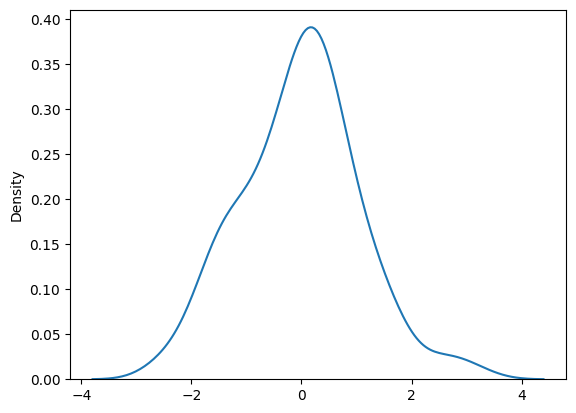

In [2]:
sample1 = np.random.normal(loc = 0, scale = 1, size = 100)
sns.kdeplot(sample1)

<Axes: ylabel='Density'>

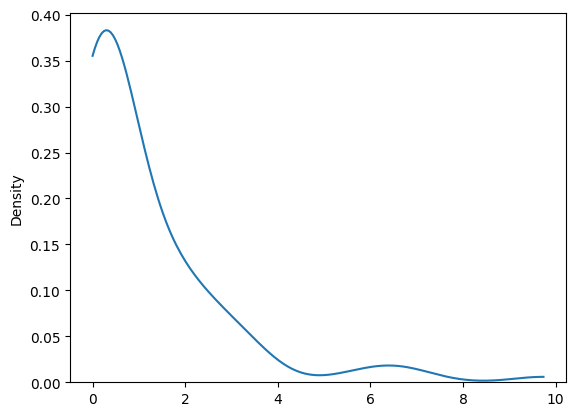

In [3]:
# Square of sample1
x = sample1**2
sns.kdeplot(x, clip = (x.min(), x.max()))

<Axes: ylabel='Density'>

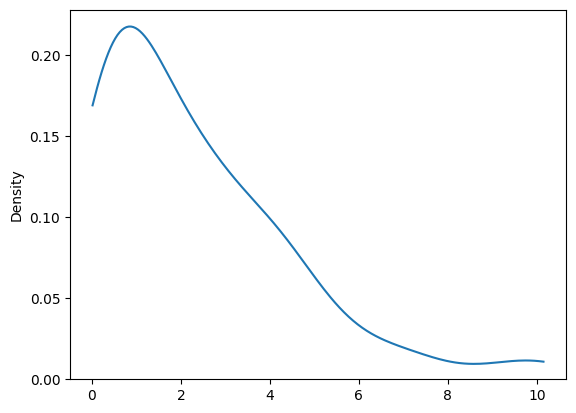

In [4]:
# Adding 2 samples

sample2 = np.random.normal(loc = 0, scale = 1, size = 100)
y = sample1**2 + sample2**2

sns.kdeplot(y, clip = (y.min(), y.max()))

<Axes: ylabel='Density'>

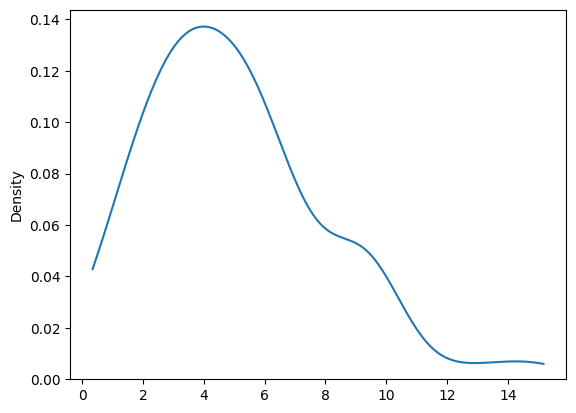

In [5]:
# Adding 5 samples

sample1 = np.random.normal(loc = 0, scale = 1, size = 100)
sample2 = np.random.normal(loc = 0, scale = 1, size = 100)
sample3 = np.random.normal(loc = 0, scale = 1, size = 100)
sample4 = np.random.normal(loc = 0, scale = 1, size = 100)
sample5 = np.random.normal(loc = 0, scale = 1, size = 100)


z = (sample1**2) + (sample2**2) + (sample3**2) + (sample4**2) + (sample5**2)

sns.kdeplot(z, clip = (z.min(), z.max()))

Text(0.5, 1.0, 'Chi-Square Distribution for 100 samples.')

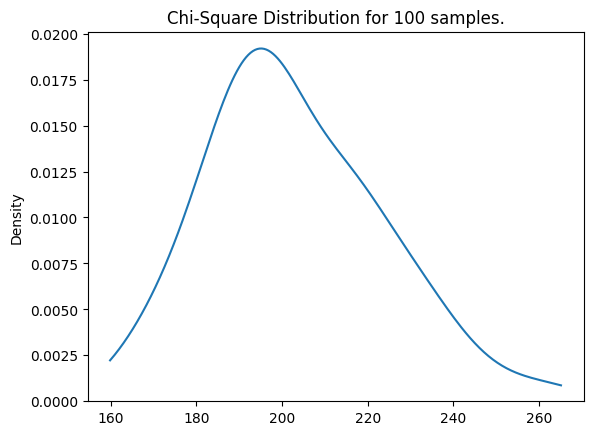

In [6]:
# Lets plot 100 samples

sample_sum = np.zeros(shape = (100))
for i in range(200):
    sample = np.random.normal(loc = 0, scale = 1, size = 100)
    sample_sum = sample_sum + sample**2

sns.kdeplot(sample_sum, clip = (sample_sum.min(), sample_sum.max()) )
plt.title("Chi-Square Distribution for 100 samples.")

# See, we are getting almost normal distribution for 100 Samples

# Goodness of Fit test
# Case Study: Titanic Dataset

In [7]:
import pandas as pd
import numpy as np

np.set_printoptions(suppress = True)
pd.set_option('display.float_format', '{:.6f}'.format)

In [8]:
df = pd.read_csv(r"00_Titanic_Dataset.csv")

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.000000,1,0,A/5 21171,7.250000,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.000000,1,0,PC 17599,71.283300,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.000000,0,0,STON/O2. 3101282,7.925000,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.000000,1,0,113803,53.100000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.000000,0,0,373450,8.050000,NaN,S


In [9]:
df.shape

(1309, 12)

<BarContainer object of 3 artists>

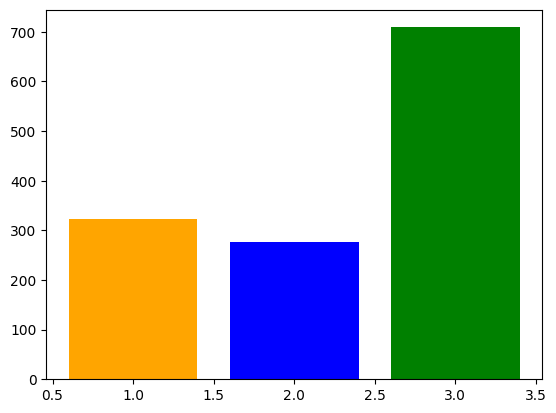

In [10]:
# Check the distribution of Pclass column.
# As this is a categorical column, we cannot plot histogram.
# So, we will plot bar graph or count plot

pclass = df['Pclass'].value_counts().sort_index()
pclass

plt.bar(pclass.index, pclass.values, color = ['orange', 'blue', 'green'])

([<matplotlib.axis.XTick at 0x164a938a390>,
 [Text(1, 0, '1'), Text(2, 0, '2'), Text(3, 0, '3')])

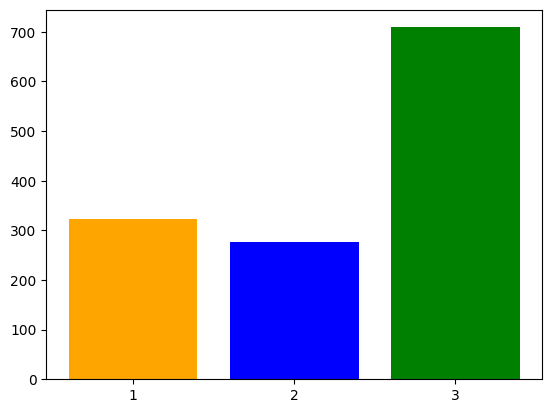

In [11]:
# Check the distribution of Pclass column.
# As this is a categorical column, we cannot plot histogram.
# So, we will plot bar graph or count plot

pclass = df['Pclass'].value_counts().sort_index()
pclass

plt.bar(pclass.index, pclass.values, color = ['orange', 'blue', 'green'])
plt.xticks(ticks = [1, 2, 3])

<Axes: xlabel='Pclass', ylabel='count'>

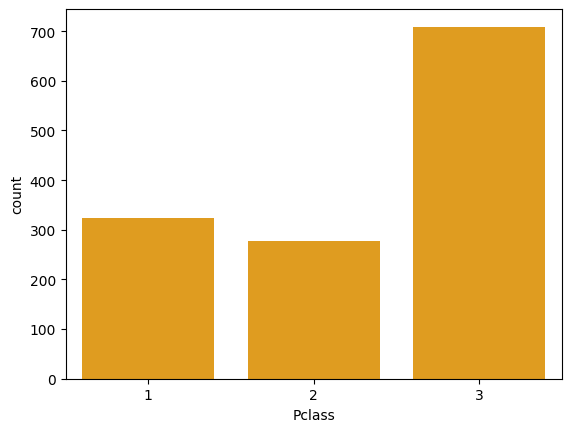

In [12]:
# Countplot plots bar graph only but it has a special feature.
# It counts the frequencies by itself. In plt.bar() we need to count frequencies manually
sns.countplot(data = df, x = 'Pclass', color = 'orange')

# Problem Statement

Here, we can clearly see that pclass is not uniformly distributed.  <br>
We will prove this using chi_square.

**We will perform the test in a sample data bcz hypothesis test is always conducted on sample data and makes predictions for the population data**

- `Null Hypothesis` = H0: Pclass has uniform distribution
- `Alternate Hypothesis` = Ha: Pclass doesn't have a uniform distribution

**Looking at the above chart, the test must reject the null hypothesis. Lets's see what is the result of the test.**

In [13]:
sample_df = df.sample(n = 500, random_state = 1)
sample_df.shape

(500, 12)

In [14]:
# Observed frequencies
obs_freq = sample_df['Pclass'].value_counts().sort_index()

# Expected/Theoritical frequencies
exp_freq = [obs_freq.sum()/3] * 3

print(obs_freq)
print()

print(exp_freq)

Pclass
1    130
2    102
3    268
Name: count, dtype: int64

[166.66666666666666, 166.66666666666666, 166.66666666666666]


In [15]:
# Find p_value

from scipy.stats import chisquare

chi2, p_value = chisquare(obs_freq, exp_freq)

print(f"""Chi-statistics: {chi2}
P_Value: {p_value}""")

Chi-statistics: 94.76800000000001
P_Value: 2.6387015337178666e-21


In [16]:
print(f"{p_value:.25f}")

0.0000000000000000000026387


In [17]:
if p_value < 0.05:
    print("We reject the null hypothesis")
else:
    print("We failed to reject the null hypothesis")


We reject the null hypothesis


# Chi Square Test Of Independence (Titanic Dataset)

**Problem Statement**: We will check if columns `Survived` and `Pclass` has any relation.

**For example**: If a person is in `Pclass` 1, 2 or 3, does this affect his survival. 

`Null Hypothesis = H0`: Both the columns are **independent** on each other (Means, has no relation)    <br>
`Alternate Hypothesis = Ha`: Both the columns are **associative** (Means, has a relation)

In [20]:
# We already took samples of 500 rows in above example.
sample_df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
201,202,0,3,"Sage, Mr. Frederick",male,NaN,8,2,CA. 2343,69.550000,NaN,S
115,116,0,3,"Pekoniemi, Mr. Edvard",male,21.000000,0,0,STON/O 2. 3101294,7.925000,NaN,S
255,256,1,3,"Touma, Mrs. Darwis (Hanne Youssef Razi)",female,29.000000,0,2,2650,15.245800,NaN,C
1103,1104,0,2,"Deacon, Mr. Percy William",male,17.000000,0,0,S.O.C. 14879,73.500000,NaN,S
195,196,1,1,"Lurette, Miss. Elise",female,58.000000,0,0,PC 17569,146.520800,B80,C
...,...,...,...,...,...,...,...,...,...,...,...,...
1179,1180,0,3,"Mardirosian, Mr. Sarkis",male,NaN,0,0,2655,7.229200,F E46,C
479,480,1,3,"Hirvonen, Miss. Hildur E",female,2.000000,0,1,3101298,12.287500,NaN,S
664,665,1,3,"Lindqvist, Mr. Eino William",male,20.000000,1,0,STON/O 2. 3101285,7.925000,NaN,S
1000,1001,0,2,"Swane, Mr. George",male,18.500000,0,0,248734,13.000000,F,S


In [22]:
# Create a contengency table for observed frequency
obs_freq = pd.crosstab(sample_df['Pclass'], sample_df['Survived'])
display(obs_freq)

Survived,0,1
Pclass,,
1,52,78
2,56,46
3,186,82


In [18]:
from scipy.stats import chi2_contingency

In [40]:
chi2_statistics, p_value, dof, exp_freq = chi2_contingency(obs_freq) 

print(f"""Chi2 Statistics: {chi2_statistics: .4f}
================
P Value: {p_value: .10f}
================
Degree of Freedom: {dof}
================
Expected Frequency:
{exp_freq}""")

Chi2 Statistics:  32.0432
P Value:  0.0000001101
Degree of Freedom: 2
Expected Frequency:
[[ 76.44   53.56 ]
 [ 59.976  42.024]
 [157.584 110.416]]


In [41]:
sig_level = 0.05   # Default significance level

if p_value < sig_level:
    print("We reject the null hypothesis")
else:
    print("We failed to reject the null hypothesis")

We reject the null hypothesis


In [43]:
df[['Pclass', 'Survived']]

,Pclass,Survived
0,3,0
1,1,1
2,3,1
3,1,1
4,3,0
...,...,...
1304,3,0
1305,1,1
1306,3,0
1307,3,0


<Axes: xlabel='Pclass', ylabel='count'>

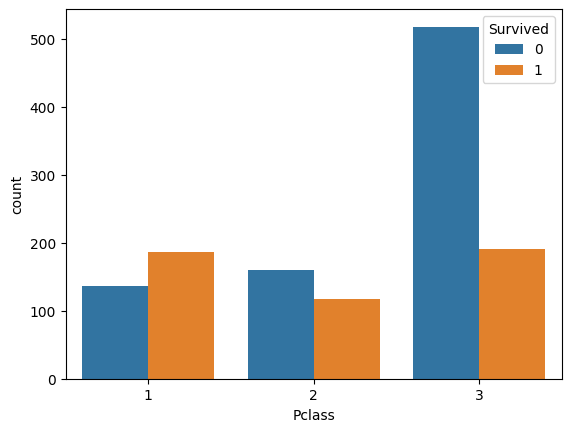

In [46]:
sns.countplot(data = df, x = 'Pclass', hue = 'Survived')

# We colcluded using Hypothesis test in sample data.
# Now let's plot countplot of Pclass and Survided column from Population data and see if our conclusion is correct.

# Session Complete